# Direct API · CORDEX North America — simplified

[Compare with the full notebook](cordex_regions_example.ipynb).


This alternative keeps the code direct: explicit paths, selected models/scenarios and ordinary calls, without fallback branches or preventive path checks. Run the notebook from the **project root**, with pyfwg, pandas, openpyxl, matplotlib, Jupyter and **Java 17+ on PATH**. Set the paths in the first code cell to your own files. Real regional baselines are required in `EPW_DIR`.

Running all cells starts Java and generates files. Opening the notebook or reading it on Read the Docs displays the saved outputs and figures without running anything. The executed example compares the original EPW with the 2050 and 2080 climate periods; these are not individual forecast years. Parameters are intentionally explicit so you can change them directly.


In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from pyfwg import enable_console_logging

JAR_DIR = Path("F:/Python/pyfwg files")
EPW_DIR = Path("build/cordex-validation/epws").resolve()
OUTPUT_DIR = Path("build/tutorial-simple/cordex_regions_example").resolve()
CACHE_DIR = Path("build/fwg-cache").resolve()
enable_console_logging(level="WARNING")


<StreamHandler stderr (NOTSET)>

## Generate the future EPWs


In [2]:
from pyfwg import morph_epw_cordex

baseline = EPW_DIR / "NAM-44.epw"
created_files = morph_epw_cordex(
    epw_paths=str(baseline),
    fwg_jar_path=str(JAR_DIR / "FutureWeatherGenerator-CORDEX-CMIP5-North-America-NAM-44-v1.2.0.jar"),
    output_dir=str(OUTPUT_DIR), temp_base_dir=str(OUTPUT_DIR / "diagnostics"),
    fwg_rcm_pairs=["CCCma-CanESM2-SMHI-RCA4"], fwg_create_ensemble=False,
    fwg_scenarios=["rcp45"], fwg_timeframes=[2050, 2080],
    fwg_output_profile="MINIMAL", fwg_interpolation_method_id="IDW",
    fwg_model_unzipped_folder=str(CACHE_DIR / "nam-simple"),
    fwg_extra_args={"threads": 1, "io_threads": 1}, delete_temp_files=False,
)
print(*created_files, sep="\n")



          MORPHING CONFIGURATION & PREVIEW
  - FWG JAR Path: F:\Python\pyfwg files\FutureWeatherGenerator-CORDEX-CMIP5-North-America-NAM-44-v1.2.0.jar
  - Final Output Directory: D:\Python\pyfwg\build\tutorial-simple\cordex_regions_example
  - EPWs to be Morphed (1 files):
    - NAM-44.epw

  For input file: NAM-44.epw
    -> Generated 'rcp45_2050.epw' will be moved to: D:\Python\pyfwg\build\tutorial-simple\cordex_regions_example\rcp45_2050.epw
    -> Generated 'rcp45_2080.epw' will be moved to: D:\Python\pyfwg\build\tutorial-simple\cordex_regions_example\rcp45_2080.epw
Configuration set. Call execute_morphing() to start the process.

-------------------- Executing FWG for NAM-44.epw --------------------
  Full Command (for reference): java -jar "F:\Python\pyfwg files\FutureWeatherGenerator-CORDEX-CMIP5-North-America-NAM-44-v1.2.0.jar" -g -epw=D:\Python\pyfwg\build\cordex-validation\epws\NAM-44.epw -output_folder=D:\Python\pyfwg\build\tutorial-simple\cordex_regions_example\diagnostics

D:\Python\pyfwg\build\tutorial-simple\cordex_regions_example\CAN_ON_Toronto-Pearson.Intl.AP_CCCma_CanESM2_SMHI_RCA4_rcp45_2050.epw
D:\Python\pyfwg\build\tutorial-simple\cordex_regions_example\CAN_ON_Toronto-Pearson.Intl.AP_CCCma_CanESM2_SMHI_RCA4_rcp45_2050.stat
D:\Python\pyfwg\build\tutorial-simple\cordex_regions_example\CAN_ON_Toronto-Pearson.Intl.AP_CCCma_CanESM2_SMHI_RCA4_rcp45_2080.epw
D:\Python\pyfwg\build\tutorial-simple\cordex_regions_example\CAN_ON_Toronto-Pearson.Intl.AP_CCCma_CanESM2_SMHI_RCA4_rcp45_2080.stat


In [3]:
future_files = {
    "RCP45 · 2050": next(OUTPUT_DIR.glob("*rcp45_2050.epw")),
    "RCP45 · 2080": next(OUTPUT_DIR.glob("*rcp45_2080.epw")),
}
comparison_title = "Toronto · NAM-44 · CCCma-CanESM2 / SMHI-RCA4"


## Original versus future temperature

The table and curves show monthly means for the same station. The right panel subtracts the original monthly mean from each future value. No uncertainty range is implied. The EPW temperature missing code is excluded from the mean. The selected test files have complete temperature records.


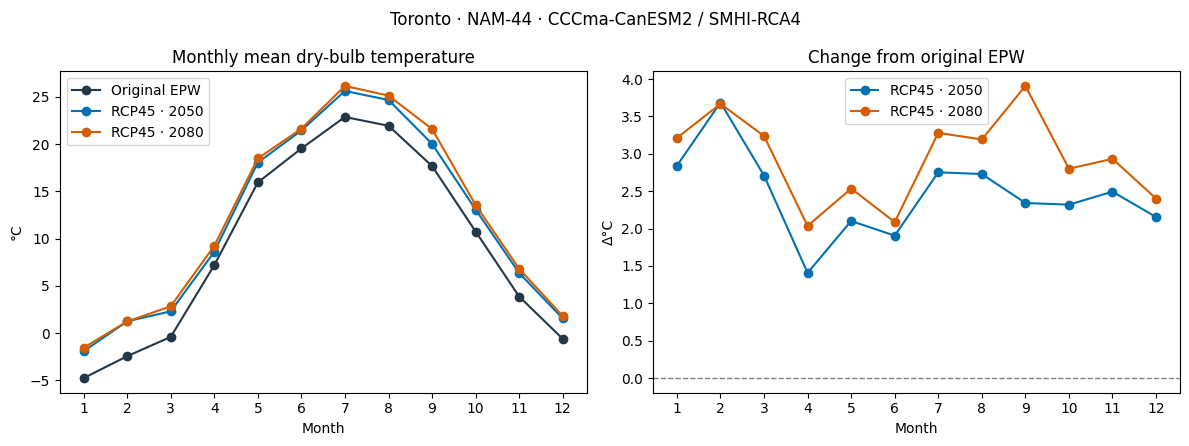

,Original EPW,RCP45 · 2050,RCP45 · 2080
month,,,
1,-4.75,-1.91,-1.54
2,-2.43,1.25,1.24
3,-0.40,2.31,2.84
4,7.19,8.60,9.23
5,15.94,18.04,18.47
6,19.53,21.44,21.62
7,22.86,25.61,26.14
8,21.93,24.66,25.12
9,17.68,20.02,21.59


In [4]:
# Read only month and dry-bulb temperature; 99.9 is the EPW missing code.
climate_files = {"Original EPW": baseline, **future_files}
monthly = pd.DataFrame({
    label: pd.read_csv(path, skiprows=8, header=None, usecols=[1, 6],
                       names=["month", "temperature"], encoding="latin-1",
                       na_values={"temperature": [99.9]}).groupby("month").temperature.mean()
    for label, path in climate_files.items()
})
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
monthly.plot(ax=axes[0], marker="o", color=["#243746", "#0072B2", "#D55E00"])
monthly.drop(columns="Original EPW").subtract(monthly["Original EPW"], axis=0).plot(
    ax=axes[1], marker="o", color=["#0072B2", "#D55E00"])
axes[0].set(title="Monthly mean dry-bulb temperature", ylabel="°C", xlabel="Month", xticks=range(1, 13))
axes[1].set(title="Change from original EPW", ylabel="Δ°C", xlabel="Month", xticks=range(1, 13))
axes[1].axhline(0, color="grey", linestyle="--", linewidth=1)
fig.suptitle(comparison_title)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "climate-comparison.png", dpi=160)
plt.show()
display(monthly.round(2))
